# Criação do Modelo 2 ( corretor )

## PASSO 2) INICIANDO CRIAÇÃO DA BASE DO CORRETOR

### 2.1) Utilização do modelo treinado no experimento do João para a seleção dos Falsos Negativos e Verdadeiros Negativos que serão utilizados no experimento do corretor

In [1]:
from unidecode import unidecode
import re
import os
import unicodedata
import pandas as pd
from joblib import load
import string
from itertools import product
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt

In [2]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kimli\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
rf_load = load('../../rf_exp2.joblib')

In [4]:
PATH_BASE_CONCATENADA_BOS_DECCC = os.getenv('PATH_BASE_CONCATENADA_BOS_DECCC')
PATH_BASE_TESTES_FINAIS = os.getenv('PATH_BASE_TESTES_FINAIS')
PATH_GABARITO_CORRETOR = os.getenv('PATH_GABARITO_CORRETOR')


PATH_BASE_FALSOS_NEGATIVOS = os.getenv('PATH_BASE_FALSOS_NEGATIVOS')
PATH_BASE_VERDADEIROS_NEGATIVOS = os.getenv('PATH_BASE_VERDADEIROS_NEGATIVOS')

### 2.1.1) Realizado o carregamento da base com dados resultado da concatenação dos arquivos BOS e DECCC

In [5]:
base_relato = pd.read_csv(PATH_BASE_CONCATENADA_BOS_DECCC)
base_relato

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,00616/2021.100190-3,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
3,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
4,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
766,00487/2020.100303-9,O RELATOR COMPARECE NESTA DIVISAO DE POLICIA ...
767,00615/2020.100363-4,A VITIMA RELATA QUE NO DIA E HORA SUPRACITADO...
768,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...
769,00615/2020.100746-2,A RELATORA COMPARECE NESTA DIVISAO DE POLICIA...


In [6]:
base_para_teste = base_relato.sample(frac=0.3, random_state=42)
base_para_teste

,n_bop,relato
671,00487/2020.100515-6,A VITIMA RELATA QUE NO 15 DE FEVEREIRO DE 202...
286,00613/2020.100011-6,RELATA NESTA DIRETORIA QUE SEU AMIGO DANIEL KO...
728,00616/2020.100235-7,A RELATORA REPRESENTANDO SEU FILHO M.D.C.L AT...
434,00487/2020.100479-0,A RELATORA COMPARECE NESTA DIVISAO DE POLICIA ...
734,00487/2020.100231-0,A RELATORA COMPARECE NESTA DIVISAO PARA REGIS...
...,...,...
706,00615/2020.100029-0,TRATA-SE DE BOLETIM DE OCORRENCIA POLICIAL RE...
622,00615/2020.100651-9,A RELATORA COMPARECE NESTA DIVISAO DE POLICIA...
198,00615/2022.100072-1,O RELATOR ACIMA QUALIFICADO COMPARECEU NESTA ...
631,00616/2020.100002-4,CONFORME MANDADO DE BUSCA PESSOAL DE LAVRA DO...


In [9]:
base_para_teste.to_csv(PATH_BASE_TESTES_FINAIS, index=False)

In [10]:
duplicates = base_relato[~base_relato.isin(base_para_teste)]
duplicates

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,NaN,NaN
3,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
4,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
766,NaN,NaN
767,NaN,NaN
768,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...
769,NaN,NaN


In [108]:
base_relato = duplicates.dropna().reset_index(drop=True)
base_relato

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
3,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
4,00615/2021.100752-2,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
535,00615/2020.100234-6,A RELATORA COMPARECEU NESTA DIVISAO PARA REGI...
536,00615/2020.100692-5,"O RELATOR PRESIDENTE DOS AUTOS, REFERENTE A O..."
537,00615/2020.100384-0,O RELATOR ACIMA IDENTIFICADO COMPARECE NESTA ...
538,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...


In [109]:
def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

In [110]:
base_relato['relato'] = base_relato['relato'].apply(normalize_text)
base_relato

,n_bop,relato
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E..."
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
2,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...
3,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
4,00615/2021.100752-2,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...
...,...,...
535,00615/2020.100234-6,A RELATORA COMPARECEU NESTA DIVISAO PARA REGI...
536,00615/2020.100692-5,"O RELATOR PRESIDENTE DOS AUTOS, REFERENTE A O..."
537,00615/2020.100384-0,O RELATOR ACIMA IDENTIFICADO COMPARECE NESTA ...
538,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...


### 2.1.3) carregamento do gabarito atualizado

Com a aquisição de novos dados para o experimento o gabarito necessitou de atualização, comportando possiveis tokens novos na base de dados DECCC. Por este motivo, agora há uma diferença entre o gabarito da construção do modelo 1 e o gabarito do modelo dois.


Em tese, não há impacto tão significativo para o experimento do modelo 1. Já que o conteúdo do gabarito sofreu um aumento do volume de dados e não uma redução.

In [ ]:
gab = pd.read_csv(PATH_GABARITO_CORRETOR)
gab.shape

(8907, 2)

### 2.1.4) Pré-processamento

Realizando o pré-processamento removendo: Stopwords, caracteres especias, números e pontuação dos relatos.

In [112]:
def preprocess(relato):
    def remove_stop_words(relato):
        # Remove stop words em português
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])

    def clean_relato(relato):
        # Remoção de números e pontuação
        relato = re.sub(r'\@(\w*\d?)', " ", relato)
        relato = re.sub(r'([A-z1-9]*_+[A-z1-9]*)|(_+[A-z1-9]*)|([A-z1-9]*_+)', " ", relato)
        relato = re.sub(r"((?:HTTPS?|WWW)(?:\:\/\/?)?[*a-zA-Z0-9\.\/\?\:@\-_=#]+[\.][a-zA-Z]{2,6}[a-zA-Z0-9\.\&\/\?\:@\-_=#]*)", " ", relato)
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

verificação do sucesso do pré-processamento

In [113]:
base_relato['relato_tratado'] = base_relato['relato'].apply(preprocess)
base_relato

,n_bop,relato,relato_tratado
0,00615/2021.100191-1,"A DECLARANTE ACIMA QUALIFICADA, INFORMA QUE E...",DECLARANTE ACIMA QUALIFICADA INFORMA PROFESSOR...
1,00616/2021.100053-9,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...,RELATORA ACIMA QUALIFICADA COMPARECE NESTA DIV...
2,00616/2021.100222-0,A RELATORA ACIMA QUALIFICADA COMPARECE NESTA ...,RELATORA ACIMA QUALIFICADA COMPARECE NESTA DIV...
3,00616/2021.100016-0,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...,RELATOR ACIMA QUALIFICADO COMPARECE NESTA DIVI...
4,00615/2021.100752-2,O RELATOR ACIMA QUALIFICADO COMPARECE NESTA D...,RELATOR ACIMA QUALIFICADO COMPARECE NESTA DIVI...
...,...,...,...
535,00615/2020.100234-6,A RELATORA COMPARECEU NESTA DIVISAO PARA REGI...,RELATORA COMPARECEU NESTA DIVISAO REGISTRAR EN...
536,00615/2020.100692-5,"O RELATOR PRESIDENTE DOS AUTOS, REFERENTE A O...",RELATOR PRESIDENTE AUTOS REFERENTE OPERACAO WH...
537,00615/2020.100384-0,O RELATOR ACIMA IDENTIFICADO COMPARECE NESTA ...,RELATOR ACIMA IDENTIFICADO COMPARECE NESTA DIV...
538,00615/2020.100847-3,A CIDADA ACIMA QUALIFICADA COMPARECEU NESTA D...,CIDADA ACIMA QUALIFICADA COMPARECEU NESTA DIVI...


### EDA - Tanto da Base para o treinamento quanto para a base dos testes

In [114]:
teste_base_relato = base_relato.copy()

def create_df(text):
    words = text.split()
    return pd.DataFrame({'pred_palavra': words})

teste1 = pd.concat(teste_base_relato['relato_tratado'].apply(create_df).tolist(), ignore_index=True)


In [115]:
teste2 = teste1.merge(gab[['palavra', 'y']], left_on='pred_palavra', right_on='palavra', how='left')


#### totas as ocorrências dos tokens

In [116]:
teste2.value_counts('y')

y
0    52095
1     5184
Name: count, dtype: int64

In [117]:
teste2[teste2['y'] == 0].shape

(52095, 3)

In [118]:
teste2[teste2['y'] == 1].shape

(5184, 3)

#### desencargo de conciência dos resultados para os testess

In [119]:
base_para_teste['relato_tratado'] = base_para_teste['relato'].apply(preprocess)

In [120]:
teste_base_relato = base_para_teste.copy()

def create_df(text):
    words = text.split()
    return pd.DataFrame({'pred_palavra': words})

teste1 = pd.concat(teste_base_relato['relato_tratado'].apply(create_df).tolist(), ignore_index=True)


In [121]:
teste2 = teste1.merge(gab[['palavra', 'y']], left_on='pred_palavra', right_on='palavra', how='left')

numero total de TODAS AS OCORRÊNCIAS DOS REGISTROS

In [122]:
teste2[teste2['y'] == 0].shape

(21604, 3)

In [123]:
teste2[teste2['y'] == 1].shape

(2135, 3)

olha como fica com o mesmo resultado da matriz

In [124]:
teste2[teste2['y'] == 0].drop_duplicates().shape

(3624, 3)

In [125]:
teste2[teste2['y'] == 1].drop_duplicates().shape

(693, 3)

### 2.1.5) Identificação dos falsos negativos

Neste trecho é realizada a identificação e criação de um DataFrame com os falsos negativos (tokens classificados como palavra '0', pelo modelo, que na verdade são nomes '1', no gabarito) após a predição dos tokens do relato relato

In [126]:
def false_negative(df_bop: pd.DataFrame):
    fn_list = []

    for n_bop, text in zip(df_bop['n_bop'], df_bop['relato_tratado']):
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])
        
        df['y_palavra'] = rf_load.predict(df['palavra'].to_list())

        df['predecessor'] = df['palavra'].shift(1).fillna('#')
        df['y_predecessor'] = df['predecessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        df['sucessor'] = df['palavra'].shift(-1).fillna('#')
        df['y_sucessor'] = df['sucessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        for _, row in df.iterrows():
            y_true_row = gab[gab['palavra'] == row['palavra']]
            y_true = y_true_row['y'].iloc[0] if not y_true_row.empty else 0
            
            if row['y_palavra'] == 0 and y_true == 1:
                fn_list.append({
                    'predecessor': row['predecessor'],
                    'y_predecessor': int(row['y_predecessor']),
                    'palavra': row['palavra'],
                    'y_palavra': int(row['y_palavra']),
                    'sucessor': row['sucessor'],
                    'y_sucessor': int(row['y_sucessor']),
                    'n_bop': n_bop
                })
                
    return pd.DataFrame(fn_list)


### 2.1.6) Identificação dos verdadeiros negativos

Neste trecho é realizada a identificação e criação de um DataFrame com os verdadeiros negativos (tokens classificados como palavra '0', pelo modelo, e que realmente são palavras '0', no gabarito) após a predição dos tokens do relato

In [127]:
def true_negative(df_bop: pd.DataFrame):
    tn_list = []

    for n_bop, text in zip(df_bop['n_bop'], df_bop['relato_tratado']):
        text = text.split()
        df = pd.DataFrame(text, columns=['palavra'])
        
        df['y_palavra'] = rf_load.predict(df['palavra'].to_list())

        df['predecessor'] = df['palavra'].shift(1).fillna('#')
        df['y_predecessor'] = df['predecessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        df['sucessor'] = df['palavra'].shift(-1).fillna('#')
        df['y_sucessor'] = df['sucessor'].apply(lambda x: df[df['palavra'] == x]['y_palavra'].iloc[0] if not df[df['palavra'] == x].empty else 2)
        
        for _, row in df.iterrows():
            y_true_row = gab[gab['palavra'] == row['palavra']]
            y_true = y_true_row['y'].iloc[0] if not y_true_row.empty else 0
            
            if row['y_palavra'] == 0 and y_true == 0:
                tn_list.append({
                    'predecessor': row['predecessor'],
                    'y_predecessor': int(row['y_predecessor']),
                    'palavra': row['palavra'],
                    'y_palavra': int(row['y_palavra']),
                    'sucessor': row['sucessor'],
                    'y_sucessor': int(row['y_sucessor']),
                    'n_bop': n_bop
                })
    return pd.DataFrame(tn_list)


In [128]:
tn_base_relatos = true_negative(base_relato)
fn_base_relatos = false_negative(base_relato)

### 2.1.7) Tratamentos das celulas vazias

Surgiu um desafio na etapa da realização da captura dos predecessores e sucessores. Foram identificados, em alguns casos, a inexistencia de um predecessor ou sucessor do token classificado. Por exemplo, 'RELATOR', que se localiza no início dos textos, é um VERDADEIRO NEGATIVO, e por ser a primeira palavra do vetor de tokens não possui predecessor. Também ocorreram problemas na captura dos FALSOS NEGATIVOS, ouve a ocorrência de dois nomes que se localizavam no fim do vetor de tokens, estas não possuiam sucessores.

Qual o problema? Devido a falta do valor do preditor acerca da palavra inexistente, ele armazena apenas '' (vazio). Isso é um problema já que os modelos utilizados trabalham apenas com dados numéricos.

Estas ocorrências, por mais raras que possa parecer, são desafios que nosso modelo deve estar preparado, visto que há sim grandes chances de ele se deparar com situações como esta em um ambiente real.

Diante disso, foi elaborada uma estratégia para tratar este erro.

Foi implementada uma nova categoria, justamente para solucionar este problema. Assim, palavras que não possuem predecessor ou sucessores, receberão como valor para os respectivos vizinhos o número inteiro '2'.

Logo, temos estas categorias para os tokens de predecessor ou sucessores:

0 - palavra  
1 - nome  
2 - predecessor ou sucessor inexistente  

##### A presença do caracter coringa

A adição do caracter coringa ocorre quando um determinado token não possue um sucessor ou predecessor. Esse evento ocorre quando se dá o início do texto e o fim do mesmo. Podemos identificar pelas ocorrências de palavras que estão sendo inseridas no início dos relatos. Não necessáriamente será realmente a primeira ou a última palavra do texto preprocessado o motivo é simples. O pré-processamento irá remover stopwords, logo não podemos nos basear pelo relato antes do pré-processamento, mas sim pelo relato após as motificações.

In [129]:
fn_base_relatos[fn_base_relatos['y_predecessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop


In [130]:
tn_base_relatos[tn_base_relatos['y_predecessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop
0,#,2,DECLARANTE,0,ACIMA,0,00615/2021.100191-1
96,#,2,RELATORA,0,ACIMA,0,00616/2021.100053-9
202,#,2,RELATORA,0,ACIMA,0,00616/2021.100222-0
242,#,2,RELATOR,0,ACIMA,0,00616/2021.100016-0
328,#,2,RELATOR,0,ACIMA,0,00615/2021.100752-2
...,...,...,...,...,...,...,...
43835,#,2,RELATORA,0,COMPARECEU,0,00615/2020.100234-6
43987,#,2,RELATOR,0,PRESIDENTE,0,00615/2020.100692-5
44016,#,2,RELATOR,0,ACIMA,0,00615/2020.100384-0
44056,#,2,CIDADA,0,ACIMA,0,00615/2020.100847-3


In [131]:
fn_base_relatos[fn_base_relatos['y_sucessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop
44,ZAHLUTH,1,BARBALHO,0,#,2,00614/2022.100007-0


In [132]:
tn_base_relatos[tn_base_relatos['y_sucessor'] == 2]

,predecessor,y_predecessor,palavra,y_palavra,sucessor,y_sucessor,n_bop
95,DEVIDAS,0,PROVIDENCIAS,0,#,2,00615/2021.100191-1
201,PROVIDENCIAS,0,CABIVEIS,0,#,2,00616/2021.100053-9
241,PROVIDENCIAS,0,CABIVEIS,0,#,2,00616/2021.100222-0
327,PROVIDENCIAS,0,CABIVEIS,0,#,2,00616/2021.100016-0
412,PROVIDENCIAS,0,CABIVEIS,0,#,2,00615/2021.100752-2
...,...,...,...,...,...,...,...
43986,LEGAIS,0,CABIVEIS,0,#,2,00615/2020.100234-6
44015,PROVIDENCIAS,0,LEGAIS,0,#,2,00615/2020.100692-5
44055,DEVIDAS,0,PROVIDENCIA,0,#,2,00615/2020.100384-0
44137,FIM,0,RELATO,0,#,2,00615/2020.100847-3


### 2.1.8) Seleção dos VERDADEIROS NEGATIVOS para o balanceamento da base

Aqui é realizada a seleção pseudo-aleatória das amostras da base de VERDADEIROS NEGATIVOS, isso é realizado pelo fato da base de verdadeiros negativos ser muito superior a base de FALSOS NEGATIVOS.  

Logo, para que ambas as bases possuam o mesmo número de amostras, foi realizada a extração 'aleatória' de 406  amostras da base de VERDADEIROS NEGATIVOS. (Faço isso aqui, pra melhorar o desempenho kakakakka)

## PASSO 3) Criação do Vetor de Bigramas dos Falsos Negativos e Verdadeiros Negativos

Este é o mesmo modelo de vetor de bigramas dos experimentos anteriores, podes visualizar logo mais a frente.

In [133]:
def bigrams_vector(lista_fn):
    alfabeto = list(string.ascii_uppercase)
    alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]
    vectorizer = CountVectorizer(analyzer='char', vocabulary=alfabeto_bigrams, lowercase=False, ngram_range=(2, 2))
    vector = vectorizer.fit_transform(lista_fn)
    return pd.DataFrame(vector.todense(), columns=alfabeto_bigrams), vectorizer

In [134]:
palavra = fn_base_relatos['palavra']
fn_vector_bigrams, vectorizer = bigrams_vector(palavra.to_list())
fn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZQ,ZR,ZS,ZT,ZU,ZV,ZW,ZX,ZY,ZZ
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
322,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
323,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
324,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
325,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [135]:
palavra = tn_base_relatos['palavra']
tn_vector_bigrams, vectorizer = bigrams_vector(palavra.to_list())
tn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZQ,ZR,ZS,ZT,ZU,ZV,ZW,ZX,ZY,ZZ
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44179,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
44180,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
44181,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
44182,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## PASSO 4) Concatenação DA PREDIÇÃO DOS FNs e TNs coletados

adiciono também os tokens pra vefificação do que foi predito

In [136]:
fn_vector_bigrams = pd.concat([fn_vector_bigrams, fn_base_relatos[['predecessor', 'y_predecessor', 'palavra','sucessor','y_sucessor']]], axis=1)
fn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,MARCOS,1,BARRETO,CNPJ,1
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,BANCO,0,SAFRA,RELATOR,0
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,BANCO,0,SAFRA,APOS,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,PLATAFORMA,0,FARIA,PIX,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,YURI,1,CAMPOS,CPF,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
322,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,KARINA,1,FRAZAO,LOPES,1
323,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,MOTOCICLETA,0,MARCA,YAMAHA,1
324,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,CELULAR,0,MARCA,MODELO,0
325,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,RENAN,1,SANTIAGOSANTOS,SILVA,1


In [137]:
tn_vector_bigrams = pd.concat([tn_vector_bigrams, tn_base_relatos[['predecessor', 'y_predecessor', 'palavra','sucessor','y_sucessor']]], axis=1)
tn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,#,2,DECLARANTE,ACIMA,0
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,DECLARANTE,0,ACIMA,QUALIFICADA,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,ACIMA,0,QUALIFICADA,INFORMA,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,QUALIFICADA,0,INFORMA,PROFESSORA,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,INFORMA,0,PROFESSORA,LINGUA,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44179,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,FILHA,1,PEDIR,QUANTIAS,0
44180,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,PEDIR,0,QUANTIAS,DINHEIRO,1
44181,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,DINHEIRO,1,REGISTRA,DEVIDOS,0
44182,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,REGISTRA,0,DEVIDOS,FINS,0


## Passo 5) Realização da Classificação Gramatical dos Falsos Negativos e Verdadeiros Positivos

In [138]:
import spacy as scy
from sklearn.preprocessing import LabelEncoder

In [139]:
nlp = scy.load('pt_core_news_lg')

In [140]:
lb = LabelEncoder()

### 5.1) Criação dos labels da classificação gramatical

No código que aproveitei do classificador do spacy, possuia a renomeação dos labels para 'pt-br', digamos assim. Por essa questão, não alterei já que a visualização se torna bem melhor para validação dos resultados exibidos pelo classificador, então foram criadas 14 labels para a classificação, estes estão listado abaixo:

In [141]:
labels = ['<SUBSTANTIVO>', '<VERBO>', '<ADJETIVO>', '<ADVERBIO>', '<PONTUACAO>',
            '<CONJUNCAO>', '<PRONOME>', '<ARTIGO>', '<PREPOSIÇÃO>', '<NUMERAL>',
            '<SIMBOLO>', '<PALAVRA ESTRANGEIRA>', '<ESPACO>', '<NULL>']

In [142]:
lb.fit(labels)

LabelEncoder()

In [143]:
lb.classes_

array(['<ADJETIVO>', '<ADVERBIO>', '<ARTIGO>', '<CONJUNCAO>', '<ESPACO>',
       '<NULL>', '<NUMERAL>', '<PALAVRA ESTRANGEIRA>', '<PONTUACAO>',
       '<PREPOSIÇÃO>', '<PRONOME>', '<SIMBOLO>', '<SUBSTANTIVO>',
       '<VERBO>'], dtype='<U21')

adicionar a modificação pra deixar esse código melhor o map que foi feito na etapa de testes do experimento do corretor

In [144]:
def renomear(doc):

    csf = []
    for token in doc:
        if token.pos_ == 'NOUN' or token.pos_ == 'PROPN':
            csf.append('<SUBSTANTIVO>')
        elif token.pos_ == 'VERB' or token.pos_ == 'AUX':
            csf.append('<VERBO>')
        elif token.pos_ == 'ADJ':
            csf.append('<ADJETIVO>')
        elif token.pos_ == 'ADV':
            csf.append('<ADVERBIO>')
        elif token.pos_ == 'PUNCT':
            csf.append('<PONTUACAO>')
        elif token.pos_ == 'CCONJ' or token.pos_ == 'SCONJ':
            csf.append('<CONJUNCAO>')
        elif token.pos_ == 'PRON':
            csf.append('<PRONOME>')
        elif token.pos_ == 'DET':
            csf.append('<ARTIGO>')
        elif token.pos_ == 'ADP':
            csf.append('<PREPOSIÇÃO>')
        elif token.pos_ == 'NUM':
            csf.append('<NUMERAL>')
        elif token.pos_ == 'SYM':
            csf.append('<SIMBOLO>')
        elif token.pos_ == 'X':
            csf.append('<PALAVRA ESTRANGEIRA>')
        elif token.pos_ == 'SPACE':
            csf.append('<ESPACO>')
    return csf


### 5.2) Tratamento dos valores vazios de predecessores e sucessores

Sim, teve dor de cabeça para os predecessores e sucessores inexistentes aqui também. Este foi solucionado de maneira mais simples.

Se observar na lista anterior de labels, podes identificar um label que não é encontrado na função de renomear, aqui em cima. Esse carinha é o <NULL>

Esse cara será a nossa classificação gramatical para os nulos, já que não tem como classificar os mesmos com nada além disso, já que eles não existem.

Logo, aqui a baixo podes ler:

Se token == '#':
    adicione na lista word_class <NULL>

tratando os nossos predecessores e sucessores vazios

In [145]:
def create_base_cg(lista_tokens):
    word_class = []
    for token in lista_tokens:
        if token == '#':
            word_class.append('<NULL>')
        else:
            lreview = token.lower()
            ldoc = nlp(lreview)
            classes = renomear(ldoc)
            for i in range(len(token.split())):
                word_class.append(classes[i])

    return pd.DataFrame({'palavra':lista_tokens, 'classe':word_class})

Aqui é onde realizo a chamada da função que irá realizar a classificação de todo mundo, tanto da palavra, quanto do predecessor e sucessor. Adicionando a mesma juntamente com o vetor de bigramas e a predição do predecessor e sucessor.

In [146]:
fn_vector_bigrams['cg_p'] = create_base_cg(fn_base_relatos['predecessor'])['classe']
fn_vector_bigrams['cg_w'] = create_base_cg(fn_base_relatos['palavra'])['classe']
fn_vector_bigrams['cg_s'] = create_base_cg(fn_base_relatos['sucessor'])['classe']

In [147]:
fn_vector_bigrams['cg_p'] = lb.transform(fn_vector_bigrams['cg_p'])
fn_vector_bigrams['cg_w'] = lb.transform(fn_vector_bigrams['cg_w'])
fn_vector_bigrams['cg_s'] = lb.transform(fn_vector_bigrams['cg_s'])
fn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,MARCOS,1,BARRETO,CNPJ,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,BANCO,0,SAFRA,RELATOR,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,BANCO,0,SAFRA,APOS,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,PLATAFORMA,0,FARIA,PIX,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,YURI,1,CAMPOS,CPF,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
322,0,0,0,0,0,0,0,0,0,0,...,0,0,KARINA,1,FRAZAO,LOPES,1,12,0,12
323,0,0,0,0,0,0,0,0,0,0,...,0,0,MOTOCICLETA,0,MARCA,YAMAHA,1,12,12,12
324,0,0,0,0,0,0,0,0,0,0,...,0,0,CELULAR,0,MARCA,MODELO,0,12,12,12
325,0,0,0,0,0,0,1,0,0,0,...,0,0,RENAN,1,SANTIAGOSANTOS,SILVA,1,12,13,12


In [148]:
tn_vector_bigrams['cg_p'] = create_base_cg(tn_base_relatos['predecessor'])['classe']
tn_vector_bigrams['cg_w'] = create_base_cg(tn_base_relatos['palavra'])['classe']
tn_vector_bigrams['cg_s'] = create_base_cg(tn_base_relatos['sucessor'])['classe']

In [149]:
tn_vector_bigrams['cg_p'] = lb.transform(tn_vector_bigrams['cg_p'])
tn_vector_bigrams['cg_w'] = lb.transform(tn_vector_bigrams['cg_w'])
tn_vector_bigrams['cg_s'] = lb.transform(tn_vector_bigrams['cg_s'])
tn_vector_bigrams

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,#,2,DECLARANTE,ACIMA,0,5,0,1
1,0,0,1,0,0,0,0,0,0,0,...,0,0,DECLARANTE,0,ACIMA,QUALIFICADA,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,ACIMA,0,QUALIFICADA,INFORMA,0,1,0,13
3,0,0,0,0,0,0,0,0,0,0,...,0,0,QUALIFICADA,0,INFORMA,PROFESSORA,0,0,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,INFORMA,0,PROFESSORA,LINGUA,1,13,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44179,0,0,0,0,0,0,0,0,0,0,...,0,0,FILHA,1,PEDIR,QUANTIAS,0,12,13,12
44180,0,0,0,0,0,0,0,0,0,0,...,0,0,PEDIR,0,QUANTIAS,DINHEIRO,1,13,12,12
44181,0,0,0,0,0,0,0,0,0,0,...,0,0,DINHEIRO,1,REGISTRA,DEVIDOS,0,12,13,13
44182,0,0,0,0,0,0,0,0,0,0,...,0,0,REGISTRA,0,DEVIDOS,FINS,0,13,13,12


In [150]:
for index, classe in zip(range(0, len(lb.classes_)), lb.classes_):
    print(str(index) + ' ' + classe)

0 <ADJETIVO>
1 <ADVERBIO>
2 <ARTIGO>
3 <CONJUNCAO>
4 <ESPACO>
5 <NULL>
6 <NUMERAL>
7 <PALAVRA ESTRANGEIRA>
8 <PONTUACAO>
9 <PREPOSIÇÃO>
10 <PRONOME>
11 <SIMBOLO>
12 <SUBSTANTIVO>
13 <VERBO>


### 5.3) Drop duplicates

remoção dos dados duplicados

In [151]:
fn_vector_bigrams.shape

(327, 684)

In [152]:
fn_vector_bigrams = fn_vector_bigrams.drop_duplicates()
fn_vector_bigrams.shape

(269, 684)

In [153]:
fn_base_final = fn_vector_bigrams
# fn_base_final = fn_vector_bigrams.drop(['sucessor', 'predecessor','palavra'], axis=1)
# fn_base_final

In [154]:
fn_base_final

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZY,ZZ,predecessor,y_predecessor,palavra,sucessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,MARCOS,1,BARRETO,CNPJ,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,BANCO,0,SAFRA,RELATOR,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,BANCO,0,SAFRA,APOS,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,PLATAFORMA,0,FARIA,PIX,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,YURI,1,CAMPOS,CPF,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
321,0,0,0,0,0,0,0,0,0,0,...,0,0,SENHORA,1,ANA,KARINA,1,12,12,12
322,0,0,0,0,0,0,0,0,0,0,...,0,0,KARINA,1,FRAZAO,LOPES,1,12,0,12
323,0,0,0,0,0,0,0,0,0,0,...,0,0,MOTOCICLETA,0,MARCA,YAMAHA,1,12,12,12
325,0,0,0,0,0,0,1,0,0,0,...,0,0,RENAN,1,SANTIAGOSANTOS,SILVA,1,12,13,12


#### Coleta de token

In [155]:
test_alfabeto = list(string.ascii_uppercase)
test_alfabeto_bigrams = [''.join(bigram) for bigram in list(product(test_alfabeto, repeat=2))]

teste = fn_base_final.iloc[[268]]

test_df_result = teste.merge(fn_base_final, on=test_alfabeto_bigrams, how='left')
test_df_result

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,cg_w_x,cg_s_x,predecessor_y,y_predecessor_y,palavra_y,sucessor_y,y_sucessor_y,cg_p_y,cg_w_y,cg_s_y
0,0,0,0,0,0,0,0,0,0,0,...,12,0,IVO,1,VANCHO,PANOVICH,1,12,12,0


In [156]:
fn_base_final = fn_vector_bigrams.drop(['sucessor', 'predecessor','palavra'], axis=1)
fn_base_final

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
321,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
322,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,12
323,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
325,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,1,12,13,12


In [157]:
tn_vector_bigrams = tn_vector_bigrams.drop_duplicates()
tn_vector_bigrams.shape

(33746, 684)

In [158]:
tn_base_final = tn_vector_bigrams.drop(['sucessor', 'predecessor','palavra'], axis=1)
tn_base_final

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,5,0,1
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,13
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44177,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,3,13,0
44178,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,0,12
44179,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,12
44180,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12


### 5.4) Armazenamento das bases prontas para treino dos Falsos Negativos e Verdadeiros Negativos

In [ ]:
fn_base_final.to_csv(PATH_BASE_FALSOS_NEGATIVOS, index=False)
tn_base_final.to_csv(PATH_BASE_VERDADEIROS_NEGATIVOS, index=False)

no fim temos estes dois arquivos

duas tabelas contendo

Parte 1: Vetor de bigramas do token (O FALSO NEGATIVO OU VERDADEIRO NEGATIVO)  
Parte 2: A resultado da predição do nosso modelo para com os predecessores e sucessores do token representado no vetor de bigramas  
Parte 3: A classificação gramatical do predecessor, da token em si e do sucessor deste token.  

In [8]:
base_fn = pd.read_csv(PATH_BASE_FALSOS_NEGATIVOS)
base_fn

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,13
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
2,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,12,12
265,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,12,0,12
266,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
267,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,1,12,13,12


In [9]:
base_tn = pd.read_csv(PATH_BASE_VERDADEIROS_NEGATIVOS)
base_tn

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,5,0,1
1,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,13
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,13,12
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33741,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,3,13,0
33742,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,0,12
33743,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,13,12
33744,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,13,12,12


## PASSO 6) Realização dos testes na base nova

In [162]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score,  recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

Realizando o carregamento das bases de falsos negativos e verdadeiros negativos criada no arquivo 'criacao_base_fn.ipynb'

In [7]:
fn_base = pd.read_csv(PATH_BASE_FALSOS_NEGATIVOS)
tn_base = pd.read_csv(PATH_BASE_VERDADEIROS_NEGATIVOS)

setando para os valores de y para o modelo

fn_base que são nossos NOMES que foram classificados como PALAVRAS recebem o rótulo '1'  
tn_base que são nossas PALAVRAS que foram classificados corretamente como PALAVRAS recebem o rótulo '0'

In [164]:
fn_base['y_true'] = 1
tn_base['y_true'] = 0

In [165]:
len(tn_base) / len(fn_base)

125.44981412639405

In [166]:
df2 = tn_base.copy()

In [167]:
count = 0
scores_kfolds = {'Accuracy' : [], 'Recall': [], 'F1-score':[], 'Precision':[]}

### Tests K-FOLDs ( Random Forest ) 

In [168]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Random Forest para treino e teste
    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)

    y_predictions['Random Forest'] = rf.predict(X_test)
    scores_kfolds['Accuracy'].append(accuracy_score(y_test, y_predictions['Random Forest']))
    scores_kfolds['Recall'].append(recall_score(y_test, y_predictions['Random Forest']))
    scores_kfolds['F1-score'].append(f1_score(y_test, y_predictions['Random Forest']))
    scores_kfolds['Precision'].append(precision_score(y_test, y_predictions['Random Forest']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

Count: 1 len df: (33477, 682)
Count: 2 len df: (33208, 682)
Count: 3 len df: (32939, 682)
Count: 4 len df: (32670, 682)
Count: 5 len df: (32401, 682)
Count: 6 len df: (32132, 682)
Count: 7 len df: (31863, 682)
Count: 8 len df: (31594, 682)
Count: 9 len df: (31325, 682)
Count: 10 len df: (31056, 682)
Count: 11 len df: (30787, 682)
Count: 12 len df: (30518, 682)
Count: 13 len df: (30249, 682)
Count: 14 len df: (29980, 682)
Count: 15 len df: (29711, 682)
Count: 16 len df: (29442, 682)
Count: 17 len df: (29173, 682)
Count: 18 len df: (28904, 682)
Count: 19 len df: (28635, 682)
Count: 20 len df: (28366, 682)
Count: 21 len df: (28097, 682)
Count: 22 len df: (27828, 682)
Count: 23 len df: (27559, 682)
Count: 24 len df: (27290, 682)
Count: 25 len df: (27021, 682)
Count: 26 len df: (26752, 682)
Count: 27 len df: (26483, 682)
Count: 28 len df: (26214, 682)
Count: 29 len df: (25945, 682)
Count: 30 len df: (25676, 682)
Count: 31 len df: (25407, 682)
Count: 32 len df: (25138, 682)
Count: 33 len df:

In [169]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

Accuracy: 0.9215308641975308
Recall: 0.9278024691358026
F1-score: 0.922132422350036
Precision: 0.9170970307399537


In [170]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

Accuracy: 0.01733354436929671
Recall: 0.01848101552312648
F1-score: 0.016613392425184437
Precision: 0.026993861473730715


Detalhe

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\3037736159.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


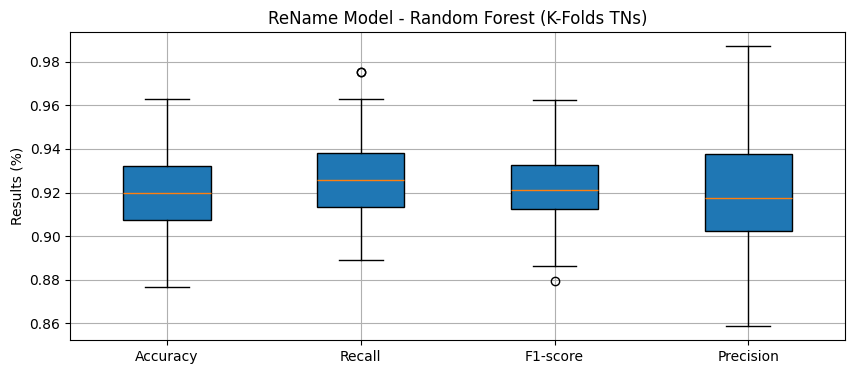

In [171]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('ReName Model - Random Forest (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\3479242761.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


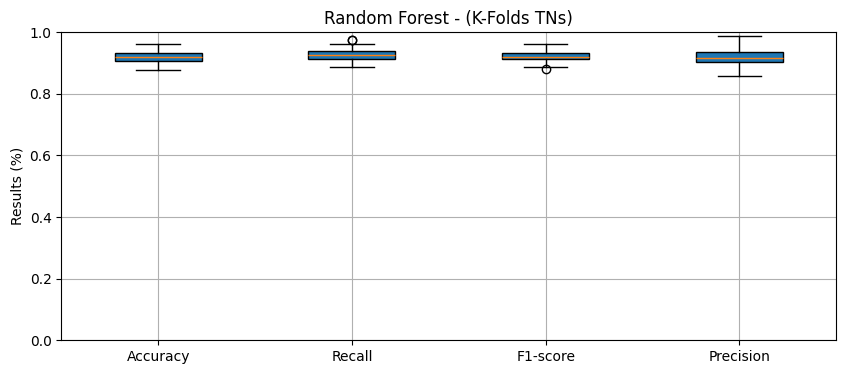

In [172]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Random Forest - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Tests K-FOLDs ( Support Vector Machine )

In [173]:
df2 = tn_base.copy()
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

In [174]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Support Vector Machine para treino e teste
    from sklearn.svm import SVC

    clf = SVC(gamma='auto', random_state=42)
    clf.fit(X_train, y_train)

    y_predictions['SVM'] = clf.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['SVM']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['SVM']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['SVM']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['SVM']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

Count: 1 len df: (33477, 682)
Count: 2 len df: (33208, 682)
Count: 3 len df: (32939, 682)
Count: 4 len df: (32670, 682)
Count: 5 len df: (32401, 682)
Count: 6 len df: (32132, 682)
Count: 7 len df: (31863, 682)
Count: 8 len df: (31594, 682)
Count: 9 len df: (31325, 682)
Count: 10 len df: (31056, 682)
Count: 11 len df: (30787, 682)
Count: 12 len df: (30518, 682)
Count: 13 len df: (30249, 682)
Count: 14 len df: (29980, 682)
Count: 15 len df: (29711, 682)
Count: 16 len df: (29442, 682)
Count: 17 len df: (29173, 682)
Count: 18 len df: (28904, 682)
Count: 19 len df: (28635, 682)
Count: 20 len df: (28366, 682)
Count: 21 len df: (28097, 682)
Count: 22 len df: (27828, 682)
Count: 23 len df: (27559, 682)
Count: 24 len df: (27290, 682)
Count: 25 len df: (27021, 682)
Count: 26 len df: (26752, 682)
Count: 27 len df: (26483, 682)
Count: 28 len df: (26214, 682)
Count: 29 len df: (25945, 682)
Count: 30 len df: (25676, 682)
Count: 31 len df: (25407, 682)
Count: 32 len df: (25138, 682)
Count: 33 len df:

In [175]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.5803456790123457
recall: 0.8806913580246913
f1_score: 0.6741807609849946
precisao: 0.5538798937784346


In [176]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.039905268100737516
recall: 0.10726335167146782
f1_score: 0.0545570817305396
precisao: 0.03944711955516812


Detalhes

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\2022981463.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


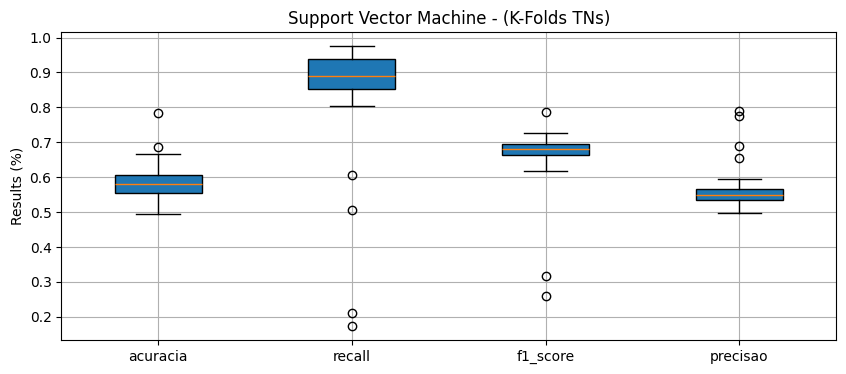

In [177]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Support Vector Machine - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\16612834.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


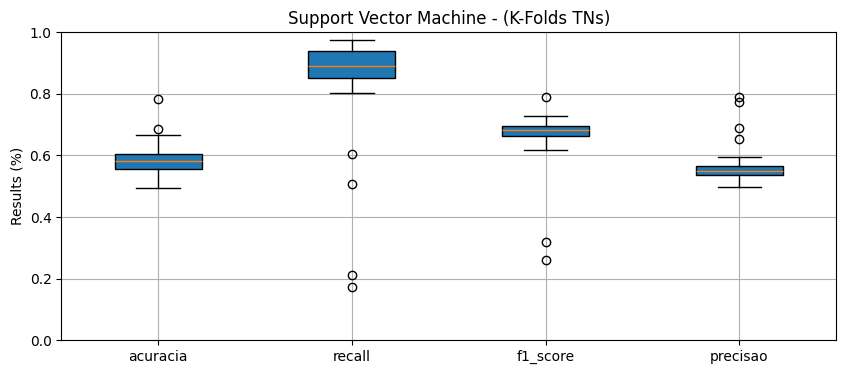

In [178]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Support Vector Machine - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Logistic Regression ( K-Folds TNs )

In [179]:
df2 = tn_base.copy()
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

In [ ]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Logistc Regression para treino e teste
    from sklearn.linear_model import LogisticRegression

    model = LogisticRegression(random_state=42)
    model.fit(X_train, y_train)

    y_predictions['Logistc Regression'] = model.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['Logistc Regression']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['Logistc Regression']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['Logistc Regression']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['Logistc Regression']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

In [181]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.8944691358024691
recall: 0.9141728395061729
f1_score: 0.8967862974773282
precisao: 0.8806718079512152


In [182]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.02067927399871317
recall: 0.012576217869698019
f1_score: 0.018732063657029046
precisao: 0.03281611669494765


Detalhes

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\3808316310.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


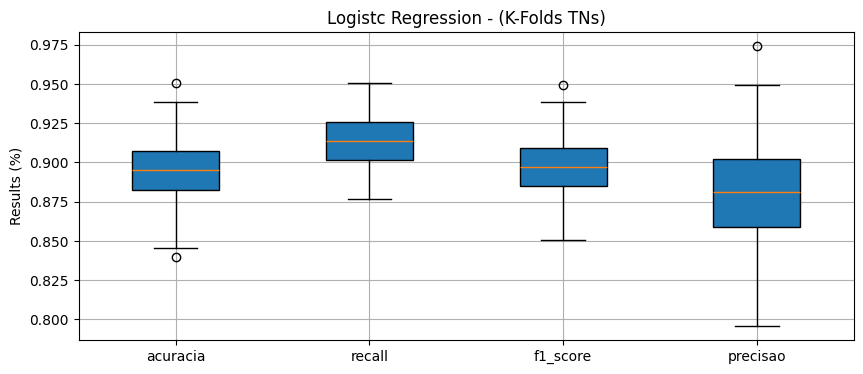

In [183]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Logistc Regression - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\978512746.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


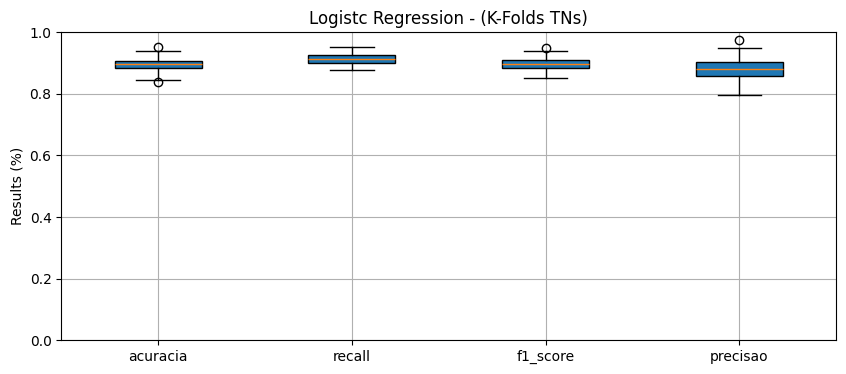

In [184]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Logistc Regression - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Gradient Boosting ( K-Folds TNs )

In [185]:
df2 = tn_base.copy()
count = 0
scores_kfolds = {'acuracia' : [], 'recall': [], 'f1_score':[], 'precisao':[]}

In [186]:
while(len(df2) >= len(fn_base)):
    buffer_df_tn = df2.sample(n=len(fn_base), random_state=42)
    
    # contat
    base_final = pd.concat([fn_base, buffer_df_tn])

    # resetando o index da base final
    base_final = base_final.reset_index(drop=True)
    
    # labels
    y = base_final['y_true']
    X = base_final.drop(['y_true'], axis=1)

    ## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
    """
    aqui é realizada a divisão da base para treino e teste

    estabelecendo o critério de divisão 30-70

    30% da base sendo utilizada para teste  
    70% da base sendo utilizada para treinamento 

    """

    # separação treino e teste
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

    def tabela_divisao(y_train, y_test):
        treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
        teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
        df_dist = pd.concat([treino, teste], axis=1)
        df_dist['Total'] = df_dist.sum(axis=1)
        pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
        return df_dist.T
    
    tabela_divisao(y_train, y_test)

    y_predictions = {}

    # selecionando Gradient Boosting para treino e teste
    from sklearn.ensemble import GradientBoostingClassifier
    gb = GradientBoostingClassifier(random_state=42)
    gb.fit(X_train, y_train)

    y_predictions['Gradient Boosting'] = gb.predict(X_test)
    scores_kfolds['acuracia'].append(accuracy_score(y_test, y_predictions['Gradient Boosting']))
    scores_kfolds['recall'].append(recall_score(y_test, y_predictions['Gradient Boosting']))
    scores_kfolds['f1_score'].append(f1_score(y_test, y_predictions['Gradient Boosting']))
    scores_kfolds['precisao'].append(precision_score(y_test, y_predictions['Gradient Boosting']))
    
    # dropando para reiniciar o ciclo
    df2 = df2.drop(buffer_df_tn.index)
    count+=1
    print("Count: " + str(count) + " len df: " + str(df2.shape))

Count: 1 len df: (33477, 682)
Count: 2 len df: (33208, 682)
Count: 3 len df: (32939, 682)
Count: 4 len df: (32670, 682)
Count: 5 len df: (32401, 682)
Count: 6 len df: (32132, 682)
Count: 7 len df: (31863, 682)
Count: 8 len df: (31594, 682)
Count: 9 len df: (31325, 682)
Count: 10 len df: (31056, 682)
Count: 11 len df: (30787, 682)
Count: 12 len df: (30518, 682)
Count: 13 len df: (30249, 682)
Count: 14 len df: (29980, 682)
Count: 15 len df: (29711, 682)
Count: 16 len df: (29442, 682)
Count: 17 len df: (29173, 682)
Count: 18 len df: (28904, 682)
Count: 19 len df: (28635, 682)
Count: 20 len df: (28366, 682)
Count: 21 len df: (28097, 682)
Count: 22 len df: (27828, 682)
Count: 23 len df: (27559, 682)
Count: 24 len df: (27290, 682)
Count: 25 len df: (27021, 682)
Count: 26 len df: (26752, 682)
Count: 27 len df: (26483, 682)
Count: 28 len df: (26214, 682)
Count: 29 len df: (25945, 682)
Count: 30 len df: (25676, 682)
Count: 31 len df: (25407, 682)
Count: 32 len df: (25138, 682)
Count: 33 len df:

In [187]:
import numpy as  np
# média dos resultados
metrica = 0
for metrica in scores_kfolds.keys(): 
    print(metrica + ": " + str(np.mean(scores_kfolds[metrica])))

acuracia: 0.8851358024691359
recall: 0.8956049382716049
f1_score: 0.8865906727632364
precisao: 0.8785523135418118


In [188]:
# desvio padrao dos resultados
idx_metrica = 0
for idx_metrica in scores_kfolds.keys(): 
    print(idx_metrica + ": " + str(np.std(scores_kfolds[idx_metrica])))

acuracia: 0.021396112474465226
recall: 0.01699970861437431
f1_score: 0.019519711937756697
precisao: 0.03401805886551776


Detalhes

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\126384097.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


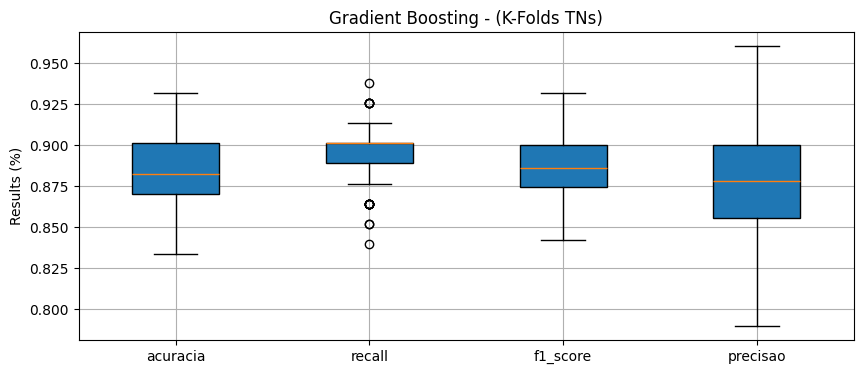

In [189]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.title('Gradient Boosting - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

Geral

C:\Users\kimli\AppData\Local\Temp\ipykernel_5240\3775361034.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)


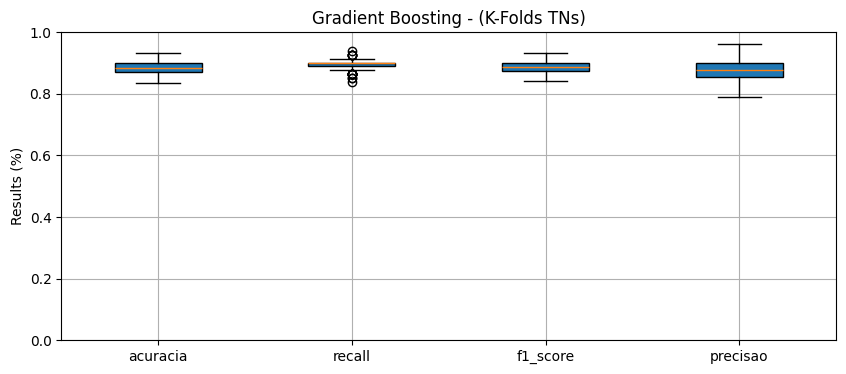

In [190]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores_kfolds.values(), labels=scores_kfolds.keys(), patch_artist=True)
plt.grid(True)
plt.ylim(0.0, 1.0)
plt.title('Gradient Boosting - (K-Folds TNs)')
plt.ylabel('Results (%)')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### Criaçao do modelo ( RANDOM FOREST )

In [191]:
tn_create_model = tn_base.sample(n=len(fn_base), random_state=42)
tn_create_model = tn_create_model.drop_duplicates(ignore_index=True)

# contat
base_final = pd.concat([fn_base, tn_create_model])

# resetando o index da base final
base_final = base_final.reset_index(drop=True)

# labels
y = base_final['y_true']
X = base_final.drop(['y_true'], axis=1)

## 6.1) Realização da divisão da base para treino e teste - (30% para treino 70% para teste)
"""
aqui é realizada a divisão da base para treino e teste

estabelecendo o critério de divisão 30-70

30% da base sendo utilizada para teste  
70% da base sendo utilizada para treinamento 

"""

# separação treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state = 42)

def tabela_divisao(y_train, y_test):
    treino = pd.DataFrame(y_train.value_counts()).rename({'count': 'Treinamento'}, axis=1).rename_axis(None, axis=0)
    teste = pd.DataFrame(y_test.value_counts()).rename({'count': 'Teste'}, axis=1).rename_axis(None, axis=0)
    df_dist = pd.concat([treino, teste], axis=1)
    df_dist['Total'] = df_dist.sum(axis=1)
    pd.concat([df_dist, df_dist.sum().to_frame('Total').T]).T
    return df_dist.T

tabela_divisao(y_train, y_test)

y_predictions = {}

#### 6.2) Realização do treino e teste dos modelos utilizando os modelos presentes no artigo.

aqui é realizado o carregamento dos algoritmos de classificação e iniciado o processo de treinamento e teste dos modelos

#### Support Vector Machine

In [192]:
from sklearn.svm import SVC

clf = SVC(gamma='auto', random_state=42)
clf.fit(X_train, y_train)

SVC(gamma='auto', random_state=42)

In [193]:
y_predictions['SVM'] = clf.predict(X_test)

In [194]:
accuracy_score(y_test, y_predictions['SVM'])

0.6

#### Random Forest

In [195]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [196]:
y_predictions['Random Forest'] = rf.predict(X_test)

In [197]:
accuracy_score(y_test, y_predictions['Random Forest'])

0.94375

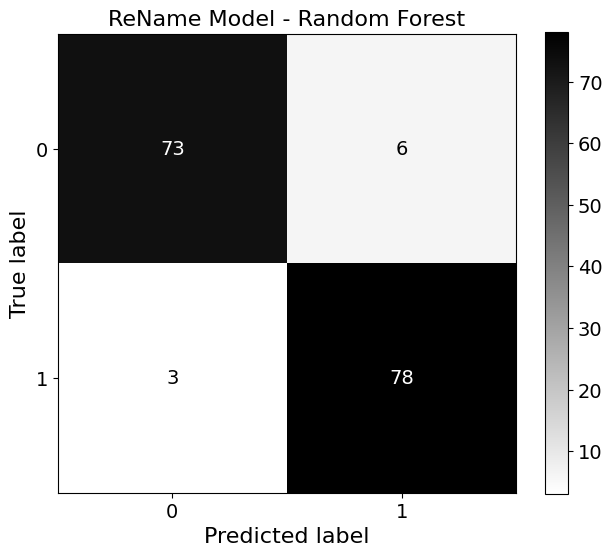

In [209]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_predictions['Random Forest'])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf.classes_)
fig, ax = plt.subplots(figsize=(7.4, 6))

disp.plot(cmap='binary', text_kw={"fontsize": 14}, ax=ax)

plt.title("ReName Model - Random Forest", fontsize=16)
plt.xlabel("Predicted label", fontsize=16)
plt.ylabel("True label", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

cbar = ax.images[-1].colorbar
cbar.ax.tick_params(labelsize=14)

plt.show()

In [102]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

y_predictions['Random Forest'] = rf.predict(X_test)

In [103]:
from sklearn.pipeline import Pipeline
from joblib import dump

In [104]:
dump(vectorizer, 'vectorizer.joblib', compress=True)

['vectorizer.joblib']

In [105]:
dump(rf, 'rf_corretor.joblib', compress=True)

['rf_corretor.joblib']

##### 6.3) Explicabilidade random forest

In [106]:
import lime
import numpy as np
import lime.lime_tabular

In [107]:
predict_fn_rf = lambda x: rf.predict_proba(x).astype(float)
X = X_train.values
# explainer = lime.lime_tabular.LimeTabularExplainer(X,feature_names = X_train.columns, discretize_continuous=True)
explainer = lime.lime_tabular.LimeTabularExplainer(X,feature_names = X_train.columns)

In [108]:
X_test

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,ZV,ZW,ZX,ZY,ZZ,y_predecessor,y_sucessor,cg_p,cg_w,cg_s
510,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,13,0,12
139,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,12,12
375,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,12,12
146,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,12,0,12
163,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,12,12,13
303,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,6,1,12
143,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,12,13
319,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,3,12


In [109]:
choosen_instance = X_test.values[0]
exp = explainer.explain_instance(choosen_instance, predict_fn_rf,num_features=10)
exp.show_in_notebook(show_all=False)

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [110]:
alfabeto = list(string.ascii_uppercase)
alfabeto_bigrams = [''.join(bigram) for bigram in list(product(alfabeto, repeat=2))]

In [111]:
teste = X_test.iloc[[0]]

df_result = teste.merge(tn_vector_bigrams, on=alfabeto_bigrams, how='left')
df_result

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,cg_w_x,cg_s_x,predecessor,y_predecessor_y,palavra,sucessor,y_sucessor_y,cg_p_y,cg_w_y,cg_s_y
0,0,0,0,0,0,0,0,0,0,0,...,0,12,COMUNICAR,0,VITIMA,CRIME,0,13,0,12
1,0,0,0,0,0,0,0,0,0,0,...,0,12,SENDO,1,VITIMA,GOLPE,0,13,0,12
2,0,0,0,0,0,0,0,0,0,0,...,0,12,COMUNICAR,0,VITIMA,CRIMES,0,13,0,12
3,0,0,0,0,0,0,0,0,0,0,...,0,12,COMUNICAR,0,VITIMA,TENTATIVA,0,13,0,12
4,0,0,0,0,0,0,0,0,0,0,...,0,12,SUPRACITADOS,0,VITIMA,CRIME,0,13,0,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,0,0,0,0,0,0,0,0,0,0,...,0,12,RODRIGUES,1,VITIMA,DIA,0,12,0,12
173,0,0,0,0,0,0,0,0,0,0,...,0,12,SANTOS,1,VITIMA,IRMAO,1,12,0,12
174,0,0,0,0,0,0,0,0,0,0,...,0,12,SENDO,1,VITIMA,RESPONDEU,0,13,0,13
175,0,0,0,0,0,0,0,0,0,0,...,0,12,JULIO,1,VITIMA,DIA,0,12,0,12


In [112]:
choosen_instance = X_test.values[40]
exp = explainer.explain_instance(choosen_instance, predict_fn_rf,num_features=10)
exp.show_in_notebook(show_all=False)
plt.savefig('2-explicabilidade_etapa_treino.png')

c:\Users\kimli\Documents\GitHub\PIBIC\corretor\corretor_env\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


<Figure size 640x480 with 0 Axes>

In [113]:
teste = X_test.iloc[[40]]

df_result = teste.merge(fn_vector_bigrams, on=alfabeto_bigrams, how='left')
df_result

,AA,AB,AC,AD,AE,AF,AG,AH,AI,AJ,...,cg_w_x,cg_s_x,predecessor,y_predecessor_y,palavra,sucessor,y_sucessor_y,cg_p_y,cg_w_y,cg_s_y
0,0,0,0,0,0,0,0,0,0,0,...,12,12,MONICA,1,TORRES,FRANCO,1,12,12,12
1,0,0,0,0,0,0,0,0,0,0,...,12,12,PAULO,1,TORRES,FRANCO,1,12,12,12
2,0,0,0,0,0,0,0,0,0,0,...,12,12,ELISSANDRA,1,TORRES,DENOMINADA,0,12,12,13
3,0,0,0,0,0,0,0,0,0,0,...,12,12,ROBERTA,1,TORRES,REPRESENTANTE,0,12,12,12
4,0,0,0,0,0,0,0,0,0,0,...,12,12,ROBERTA,1,TORRES,PEDIU,0,12,12,13


In [ ]:
for i in range(len(X_test)):  # Não precisa do range(0, ...)
    teste = X_test.iloc[[i]]

    df_result = teste.merge(fn_vector_bigrams, on=alfabeto_bigrams, how='left')

    if not df_result[df_result['palavra'] == "TORRES"].empty:
        print(i)

40


#### Logistic Regression

In [114]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [115]:
y_predictions['Logistic Regression'] = model.predict(X_test)

In [116]:
accuracy_score(y_test, y_predictions['Logistic Regression'])

0.94375

#### Gradient Boosting

In [117]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [118]:
y_predictions['Gradient Boosting'] = gb.predict(X_test)

In [119]:
accuracy_score(y_test, y_predictions['Gradient Boosting'])

0.9125

## PASSO 7) Apresentação dos resultados

### 7.1) Confusion Matrix

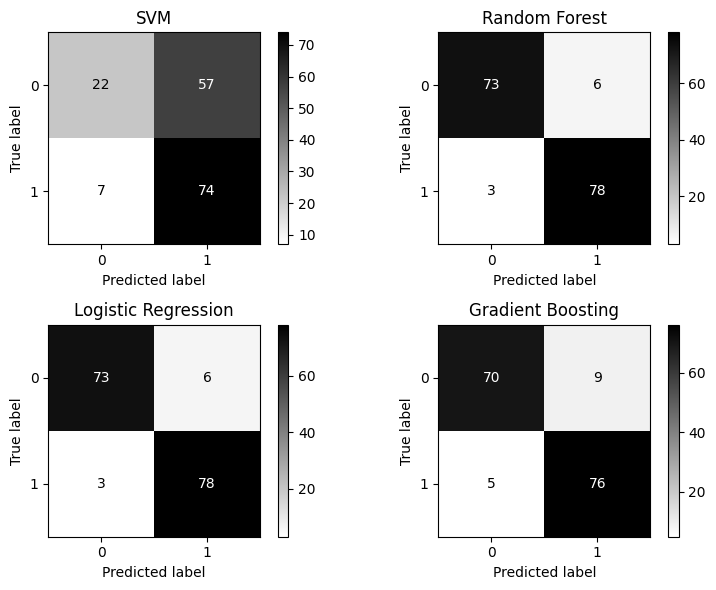

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(8, 6))

for model_name, y_pred, ax in zip(y_predictions.keys(), y_predictions.values(), axs.flat):
    cm = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=clf.classes_, )
    cm.plot(ax=ax, cmap='binary', values_format='d')
    ax.grid(False)
    ax.set_title(model_name)
plt.tight_layout()
# plt.savefig('imagens/matriz_confusao.png', bbox_inches='tight', dpi = 300)

In [121]:
dfs = {}
for model_name, y_pred in y_predictions.items():
    report = {}
    report['accuracy'] = accuracy_score(y_test, y_pred)
    report['precision'] = precision_score(y_test, y_pred)
    report['recall'] = recall_score(y_test, y_pred)
    report['f1-score'] = f1_score(y_test, y_pred)
    dfs[model_name] = pd.DataFrame(report, index=[model_name])

### 7.2) Metrics - ACCURACY, PRECISION, RECALL, F1-SCORE

In [122]:
concatenated_df = pd.concat(dfs.values())
concatenated_df

,accuracy,precision,recall,f1-score
SVM,0.60000,0.564885,0.913580,0.698113
Random Forest,0.94375,0.928571,0.962963,0.945455
Logistic Regression,0.94375,0.928571,0.962963,0.945455
Gradient Boosting,0.91250,0.894118,0.938272,0.915663


In [123]:
plt.style.use('bmh')

### 7.3) Comparação métricas dos algoritmos

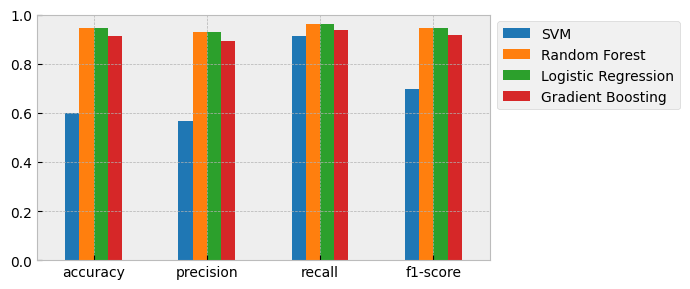

In [124]:
concatenated_df.T.plot.bar(figsize=(7, 3), ylim=(0, 1.0), color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], grid=1).legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.tight_layout()

## PASSO 8) Realização da Validação cruzada

In [121]:
def validacao_cruzada(X_train, y_train, models):
    cv_results= {}
    scores = {}

    for model_name, model in models.items():
        score = cross_val_score(estimator=model, X=X_train, y=y_train, cv=10)
        media = score.mean()
        desvio = score.std()
        scores[model_name] = score
        cv_results[model_name] = {'Validação Cruzada': "%.5f" % media, 'Desvio Padrão': "%.5f" % desvio}
        
    return cv_results, scores

In [ ]:
cv_results, scores = validacao_cruzada(X_train, y_train,{
    'SVC': SVC(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
})

#### comentários a cerca do boxplot


Observando o resultado da validação cruzada, podemos observar o comportamento do algoritmo quando o mesmo se depara com diferentes conjuntos de dados para o treinamento.

Destaque para o Random Forest que possuiu pouca variância se comparado com os outros modelos.

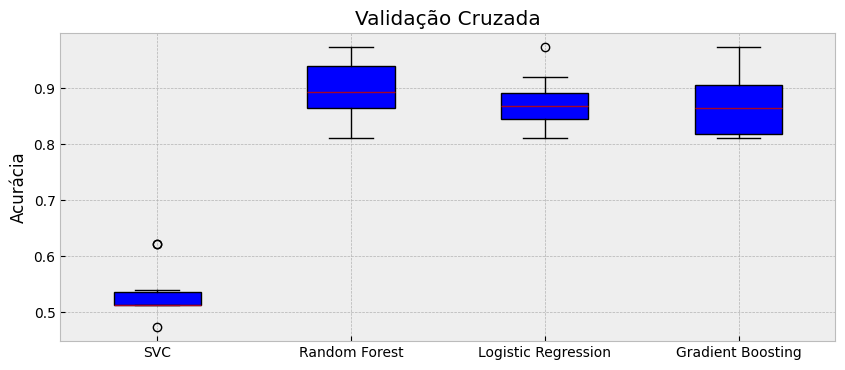

In [123]:
plt.figure(figsize=(10, 4))
plt.boxplot(scores.values(), tick_labels=scores.keys(), patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
# plt.savefig('images/boxplot.png', bbox_inches='tight', dpi = 300)
plt.show()

### 8.1) Média e Desvio Padrão dos resultados obtidos na validação cruzada

está em ordem desc

In [124]:
scores

{'SVC': array([0.47368421, 0.52631579, 0.62162162, 0.51351351, 0.51351351,
        0.54054054, 0.51351351, 0.51351351, 0.51351351, 0.62162162]),
 'Random Forest': array([0.94736842, 0.89473684, 0.97297297, 0.89189189, 0.86486486,
        0.86486486, 0.81081081, 0.91891892, 0.94594595, 0.86486486]),
 'Logistic Regression': array([0.86842105, 0.86842105, 0.97297297, 0.89189189, 0.83783784,
        0.89189189, 0.81081081, 0.83783784, 0.91891892, 0.86486486]),
 'Gradient Boosting': array([0.84210526, 0.92105263, 0.97297297, 0.86486486, 0.81081081,
        0.86486486, 0.81081081, 0.81081081, 0.91891892, 0.86486486])}

####  Media ( validaçao cruzada )

In [125]:
np.mean(scores['Random Forest'])

np.float64(0.897724039829303)

In [126]:
np.mean(scores['Logistic Regression'])

np.float64(0.8763869132290185)

In [127]:
np.mean(scores['Gradient Boosting'])

np.float64(0.8682076813655761)

In [128]:
np.mean(scores['SVC'])

np.float64(0.5351351351351351)

#### Desvio Padrão ( validaçao cruzada )

In [129]:
np.std(scores['Random Forest'])

np.float64(0.04662356107346515)

In [130]:
np.std(scores['Logistic Regression'])

np.float64(0.043761401115087126)

In [131]:
np.std(scores['Gradient Boosting'])

np.float64(0.051901875162686156)

In [132]:
np.std(scores['SVC'])

np.float64(0.04602229100997585)